# H1 · The power law (*Zero to One*, ch. 7)

> "The biggest secret in venture capital is that the best investment in a successful fund equals or outperforms the entire rest of the fund combined."

The chapter makes three claims, which we test separately:

| Claim | Test | Data |
|---|---|---|
| **H1a.** Company outcomes follow a power law, not a bell curve. | Maximum-likelihood tail fit of firm size each year from 2011 to 2025 (Clauset, Shalizi & Newman 2009), and a test against the lognormal alternative. | SEC XBRL `dei:EntityPublicFloat`, all filers |
| **H1b.** A handful of firms create almost all the value. | Wealth created from 2014 (the book's year) to the latest year: how many firms account for all of the net gain? This follows Bessembinder (2018). | Same |
| **H1c.** In a portfolio, the single best holding returns as much as all the others combined. | (i) Simulated 25-company portfolios of small public firms bought in 2014. (ii) Within each Y Combinator batch: does the largest company outweigh the rest of the batch combined? | SEC; the Y Combinator directory |

**Since publication.** If Thiel is right, and the forces he describes (network effects, economies of scale) have strengthened, the tail should have become *heavier* after 2014. A heavier tail means a lower α, a higher top-10 share, and fewer firms accounting for all the gains.

**Measurement caveats**
- *Public float* is the market value of shares held by non-affiliates. It excludes insider stakes, so founder-controlled firms look smaller than they are.
- A change in float also reflects new share issuance and buybacks, not only returns.
- A firm that leaves the data may have been acquired (often at a premium) or may have failed, and the SEC frames do not say which. We therefore report two bounds, one treating exits as worth zero and one treating them as worth their 2014 value.
- Y Combinator team sizes are self-reported and some are out of date. Team size stands in for value, and it is only a rough measure of it.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
import thiel_common as tc
tc.style()
print("synthetic mode" if tc.SYNTHETIC else "live data")

live data


## Part A · Public companies

The first run makes 76 requests to SEC: 60 for public float (15 years × 4 quarters) and 16 for total assets, which are used to screen out scale errors, at a pace of about 7 per second. Later runs read from the cache.

In [2]:
# 2011 start: smaller filers only began tagging dei:EntityPublicFloat in mid-2011 (2010 has ~2,300 filers)
panel = tc.public_float_panel(range(2011, 2026))
fixes = tc.SCALE_FIXES
tc.save_table(fixes, "h1_scale_fixes", index=False)
print("Scale-error repairs:", fixes.action.value_counts().to_dict())
print(fixes.sort_values("val", ascending=False).head(8).assign(val_bn=lambda d: (d.val / 1e9).round(0))
      [["entityName", "year", "val_bn", "action"]].to_string(index=False))
counts = panel.groupby("year").size()
print(counts.to_string())

# Late filers make the newest year incomplete. Use the last year with at least 90% of the prior three years' median count.
ok = [y for y in counts.index if y < 2013 or counts[y] >= 0.9 * counts.loc[y - 3:y - 1].median()]
END = max(ok); BASE = 2014
print(f"\nBase year {BASE}; end year {END} ({counts[END]:,} filers)")
big = panel[panel.year == END].nlargest(5, "val")[["entityName", "val"]]
print(big.assign(val_bn=lambda d: (d.val / 1e9).round(0)).drop(columns="val").to_string(index=False))

Scale-error repairs: {'rescaled /1000': 432, 'rescaled x1000': 265, 'rescaled /1000 (assets check)': 184, 'dropped': 156, 'dropped (assets check)': 5}
            entityName  year  val_bn         action
 The AZEK Company Inc.  2024  7159.0 rescaled x1000
  ONTO INNOVATION INC.  2023  5660.0        dropped
  CHAMPION HOMES, INC.  2024  5354.0        dropped
          NOVANTA INC.  2023  5034.0        dropped
CELSIUS HOLDINGS, INC.  2022  4935.0        dropped
      CleanSpark, Inc.  2024  4883.0        dropped
          NOVANTA INC.  2021  4835.0        dropped
  ONTO INNOVATION INC.  2025  4817.0        dropped
year
2011    5901
2012    6044
2013    5799
2014    5780
2015    5538
2016    5260
2017    5083
2018    5016
2019    4907
2020    5035
2021    5642
2022    5573
2023    5095
2024    4802
2025    4639

Base year 2014; end year 2025 (4,639 filers)
           entityName  val_bn
          NVIDIA CORP  4000.0
MICROSOFT CORPORATION  3600.0
           Apple Inc.  3253.0
     AMAZON.COM

### H1a · Is the size distribution a power law, and has the tail become heavier since 2014?

* **α (top 500)** is fitted to the 500 largest firms every year, so the tail being measured is comparable over time. This is the series to read for the trend. The free-x_min fit picks its own cut-off each year, and that cut-off moves a lot (from about $6bn to over $100bn), so it is shown for reference only.
* **α** is the exponent of the density's upper tail. Zipf's law corresponds to α ≈ 2. A lower α means a heavier tail, where the giants are bigger relative to everyone else.
* **R** is the normalised log-likelihood ratio of a power-law fit against a lognormal fit. R > 0 favours the power law, R < 0 favours the lognormal, and **p** says whether the sign is statistically reliable. Firm-size data often cannot tell the two apart; if so, we say so.

In [3]:
rows, fits = [], {}
for y, g in panel.groupby("year"):
    v = g.val.values
    f = tc.tail_fit(v)
    cmp_ = tc.compare_tails(f["fit"])
    f500 = tc.tail_fit(v, xmin=np.sort(v)[-500])            # fixed tail: the 500 largest firms
    fits[y] = f
    rows.append({"year": y, "n_firms": len(v), "alpha_top500": f500["alpha"], "alpha_top500_se": f500["se"],
                 "alpha": f["alpha"], "alpha_se": f["se"],
                 "xmin_bn": f["xmin"] / 1e9, "n_tail": f["n_tail"],
                 "R_pl_vs_lognormal": cmp_["R_pl_vs_lognormal"], "p": cmp_["p"],
                 "top10_share": tc.top_share(v, k=10), "top1pct_share": tc.top_share(v, frac=0.01),
                 "total_float_tn": v.sum() / 1e12})
dist = pd.DataFrame(rows).set_index("year")
tc.save_table(dist, "h1a_distribution_by_year")
pre, post = dist.loc[2011:2014], dist.loc[2015:END]
print(f"alpha, top 500: mean {pre.alpha_top500.mean():.2f} (2011-14) vs {post.alpha_top500.mean():.2f} (2015-{END})")
print(f"alpha, MLE x_min: mean {pre.alpha.mean():.2f} (2011-14) vs {post.alpha.mean():.2f} (2015-{END})")
print(f"top-10 share: {dist.top10_share[BASE]:.1%} in {BASE} -> {dist.top10_share[END]:.1%} in {END}")
dist.round(3)

alpha, top 500: mean 1.94 (2011-14) vs 1.88 (2015-2025)
alpha, MLE x_min: mean 2.12 (2011-14) vs 2.09 (2015-2025)
top-10 share: 14.3% in 2014 -> 33.2% in 2025


,n_firms,alpha_top500,alpha_top500_se,alpha,alpha_se,xmin_bn,n_tail,R_pl_vs_lognormal,p,top10_share,top1pct_share,total_float_tn
year,,,,,,,,,,,,
2011,5901,1.935,0.042,2.135,0.071,11.586,254,-1.552,0.121,0.150,0.419,14.912
2012,6044,1.931,0.042,2.134,0.072,11.803,249,-1.141,0.254,0.168,0.445,15.240
2013,5799,1.947,0.042,2.120,0.069,13.500,266,-1.592,0.111,0.148,0.416,18.349
2014,5780,1.949,0.042,2.107,0.062,13.683,318,-1.785,0.074,0.143,0.399,21.804
2015,5538,1.917,0.041,1.883,0.035,5.591,629,-3.179,0.001,0.141,0.394,22.890
2016,5260,1.892,0.040,2.140,0.076,20.000,227,-1.578,0.114,0.157,0.414,22.514
2017,5083,1.933,0.042,1.884,0.036,6.494,597,-3.066,0.002,0.169,0.402,25.452
2018,5016,1.923,0.041,1.942,0.042,9.399,493,-2.173,0.030,0.183,0.416,28.673
2019,4907,1.892,0.040,2.190,0.088,31.446,185,-1.120,0.263,0.197,0.422,29.295


### Figure H1-1 · The tail in the year of the book and today

The complementary cumulative distribution P(X ≥ x) is plotted on log–log axes. A power law appears as a straight line in the tail. The dashed lines are the maximum-likelihood fits, drawn from their estimated x_min.

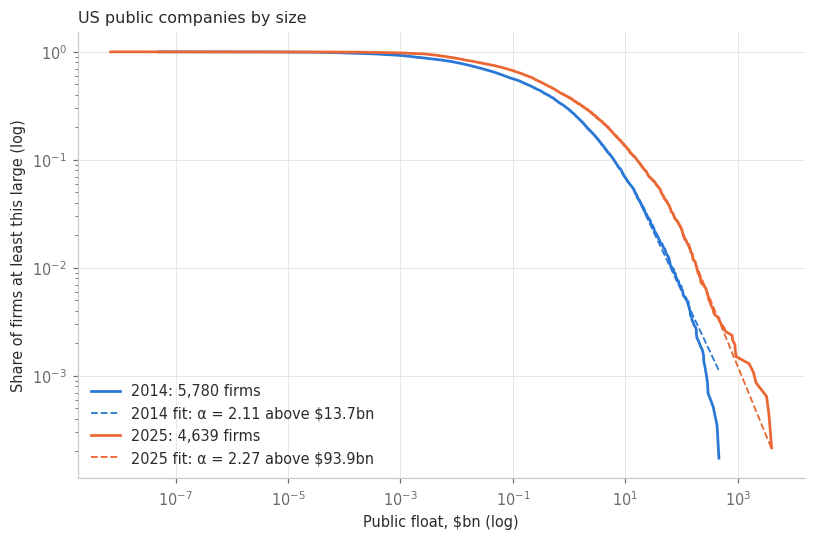

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for i, y in enumerate([BASE, END]):
    v = panel.loc[panel.year == y, "val"].values
    x, p = tc.ccdf(v)
    ax.loglog(x / 1e9, p, color=tc.C[i], lw=1.8, label=f"{y}: {len(v):,} firms")
    f = fits[y]; xm = f["xmin"]; frac = (v >= xm).mean()
    xx = np.logspace(np.log10(xm), np.log10(v.max()), 50)
    ax.loglog(xx / 1e9, frac * (xx / xm) ** (1 - f["alpha"]), color=tc.C[i], ls="--", lw=1.2,
              label=f"{y} fit: α = {f['alpha']:.2f} above ${xm/1e9:.1f}bn")
ax.set_xlabel("Public float, $bn (log)"); ax.set_ylabel("Share of firms at least this large (log)")
ax.set_title("US public companies by size", loc="left"); ax.legend(loc="lower left")
fig.tight_layout(); tc.save_fig(fig, "h1_fig1_ccdf")

### Figure H1-2 · Has concentration increased since publication?

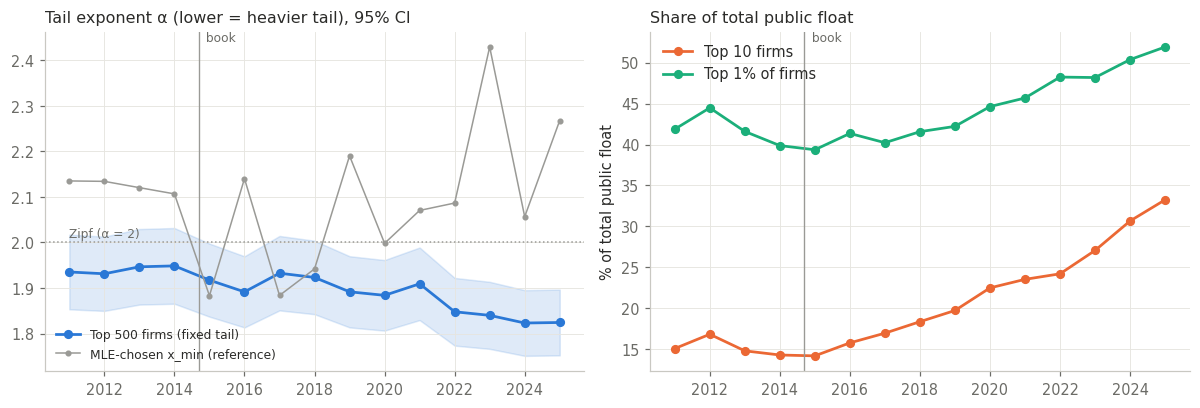

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(dist.index, dist.alpha_top500, color=tc.C[0], marker="o", ms=5, label="Top 500 firms (fixed tail)")
ax.fill_between(dist.index, dist.alpha_top500 - 1.96 * dist.alpha_top500_se, dist.alpha_top500 + 1.96 * dist.alpha_top500_se,
                color=tc.C[0], alpha=0.15)
ax.plot(dist.index, dist.alpha, color=tc.GREY, marker="o", ms=3, lw=1, label="MLE-chosen x_min (reference)")
ax.legend(loc="lower left", fontsize=8)
ax.axhline(2, color=tc.GREY, ls=":", lw=1); ax.text(dist.index[0], 2.005, "Zipf (α = 2)", fontsize=8, color=tc.MUTED, va="bottom")
ax.set_title("Tail exponent α (lower = heavier tail), 95% CI", loc="left")
ax = axes[1]
ax.plot(dist.index, dist.top10_share * 100, color=tc.C[1], marker="o", ms=5, label="Top 10 firms")
ax.plot(dist.index, dist.top1pct_share * 100, color=tc.C[2], marker="o", ms=5, label="Top 1% of firms")
ax.set_ylabel("% of total public float"); ax.legend(loc="upper left")
ax.set_title("Share of total public float", loc="left")
for a in axes:
    a.axvline(BASE + 0.7, color=tc.GREY, lw=0.9); a.text(BASE + 0.8, a.get_ylim()[1], " book", fontsize=8, color=tc.MUTED, va="top")
fig.tight_layout(); tc.save_fig(fig, "h1_fig2_concentration")

### H1b · How many firms created the wealth from 2014 to the end year?

Every 2014 filer is tracked to the end year.
* **Survivors** (present in both years) contribute their change in float.
* **Exits** (present in 2014, absent at the end) are treated two ways. *Lower bound:* the exit is worth 0, a loss of the full 2014 float. *Neutral:* the exit is worth its 2014 float, a change of zero.
* **Entrants** (IPOs after 2014) are reported separately. They are new value, but they were not available to a 2014 investor.

The Bessembinder-style statistic is **k**: the smallest number of the best-performing firms whose combined gain equals the net gain of the whole 2014 cohort.

In [6]:
# Nearest-year values: a filing can land outside one year's frames (e.g. Oracle has no 2025 frame value)
a = tc.value_near(panel, BASE, (0, -1, 1))
b = tc.value_near(panel, END, (0, -1))
names = panel.sort_values("year").groupby("cik").entityName.last()
surv = a.index.intersection(b.index)
d_surv = (b[surv] - a[surv]).sort_values(ascending=False)
exits = a.index.difference(b.index)
entr = b.index.difference(a.index)

def k_for_all(gains, total):
    c = np.cumsum(np.sort(gains)[::-1])
    tol = total * (1 - 1e-9)                      # cumsum vs sum rounding
    return int(np.argmax(c >= tol) + 1) if total > 0 and c[-1] >= tol else np.nan

net_neutral = d_surv.sum()
net_lower = d_surv.sum() - a[exits].sum()
cohort_n = len(a)
wc = pd.Series({
    "firms_2014": cohort_n, "survivors": len(surv), "exits": len(exits), "entrants": len(entr),
    "survivor_share_losing_pct": 100 * (d_surv < 0).mean(),
    "net_gain_neutral_tn": net_neutral / 1e12, "net_gain_lower_tn": net_lower / 1e12,
    "entrant_value_tn": b[entr].sum() / 1e12,
    "k_all_gain_neutral": k_for_all(d_surv.values, net_neutral),
    "k_all_gain_lower": k_for_all(d_surv.values, net_lower),
    "top10_share_of_net_neutral_pct": 100 * d_surv.head(10).sum() / net_neutral,
})
wc["k_pct_of_2014_cohort_neutral"] = 100 * wc.k_all_gain_neutral / cohort_n
wc["k_pct_of_2014_cohort_lower"] = 100 * wc.k_all_gain_lower / cohort_n
tc.save_table(wc.to_frame("value"), "h1b_wealth_creation")
top = pd.DataFrame({"firm": names[d_surv.index[:15]].values, "gain_bn": (d_surv.values[:15] / 1e9).round(0),
                    "cum_share_of_net_pct": (100 * d_surv.cumsum().values[:15] / net_neutral).round(1)})
tc.save_table(top, "h1b_top15_creators", index=False)
print(wc.round(2).to_string()); top

firms_2014                        6964.00
survivors                         2879.00
exits                             4085.00
entrants                          2291.00
survivor_share_losing_pct           35.19
net_gain_neutral_tn                 36.66
net_gain_lower_tn                   32.56
entrant_value_tn                     6.33
k_all_gain_neutral                 401.00
k_all_gain_lower                   155.00
top10_share_of_net_neutral_pct      49.88
k_pct_of_2014_cohort_neutral         5.76
k_pct_of_2014_cohort_lower           2.23


,firm,gain_bn,cum_share_of_net_pct
0,NVIDIA CORP,3991.0,10.9
1,MICROSOFT CORPORATION,3235.0,19.7
2,Apple Inc.,2791.0,27.3
3,"AMAZON.COM, INC.",1995.0,32.8
4,Alphabet Inc.,1610.0,37.2
5,"Meta Platforms, Inc.",1456.0,41.1
6,Broadcom Inc.,923.0,43.7
7,"Tesla, Inc.",870.0,46.0
8,ELI LILLY AND COMPANY,747.0,48.1
9,BERKSHIRE HATHAWAY INC,668.0,49.9


### Figure H1-3 · Cumulative wealth creation by firm rank, 2014 to the end year

Firms are ranked by dollar gain. The curve rises above 100% because the gains of the winners also offset the losses of everyone else. The point where it crosses 100% is **k**.

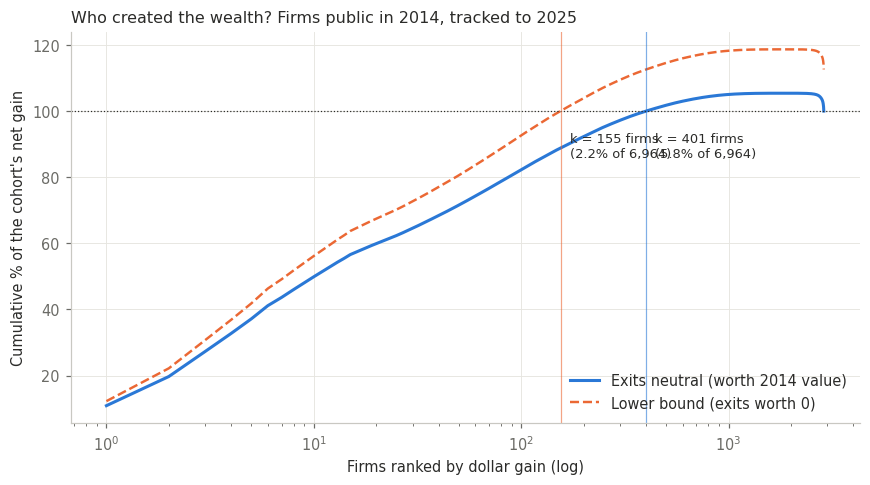

In [7]:
cum = 100 * d_surv.cumsum().values / net_neutral
rank = np.arange(1, len(cum) + 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(rank, cum, color=tc.C[0], lw=2, label="Exits neutral (worth 2014 value)")
ax.semilogx(rank, 100 * d_surv.cumsum().values / net_lower, color=tc.C[1], lw=1.6, ls="--",
            label="Lower bound (exits worth 0)")
ax.axhline(100, color=tc.INK, lw=0.8, ls=":")
for kk, col in [(wc.k_all_gain_neutral, tc.C[0]), (wc.k_all_gain_lower, tc.C[1])]:
    if not np.isnan(kk):
        ax.axvline(kk, color=col, lw=0.8, alpha=0.6)
        ax.annotate(f"k = {int(kk)} firms\n({100*kk/cohort_n:.1f}% of {cohort_n:,})", (kk, 100), xytext=(6, -30),
                    textcoords="offset points", fontsize=8.5)
ax.set_xlabel("Firms ranked by dollar gain (log)"); ax.set_ylabel("Cumulative % of the cohort's net gain")
ax.set_title(f"Who created the wealth? Firms public in {BASE}, tracked to {END}", loc="left")
ax.legend(loc="lower right"); fig.tight_layout(); tc.save_fig(fig, "h1_fig3_wealth_creation")

### H1c (i) · Does the best holding outweigh the rest of the portfolio?

We simulate a venture-style investor in 2014. Each portfolio holds 25 equal stakes drawn at random from **small** public firms (2014 float between $25m and $500m). Each holding's outcome is its multiple: float in the end year divided by float in 2014, with exits valued at 0 or at 1×.

Thiel's claim concerns *successful* funds, so we report the share of portfolios whose best holding is worth at least as much as the other 24 combined, (a) for all portfolios and (b) for the top quartile by total multiple. For contrast we run the same simulation on large firms (2014 float above $10bn), where outcomes should be far less skewed.

In [8]:
rng = np.random.default_rng(2014)
def simulate(universe, exit_mult, n_port=20000, size=25):
    m = (b.reindex(universe) / a[universe]).fillna(exit_mult).values
    m = np.clip(m, 0, None)
    draws = m[rng.integers(0, len(m), (n_port, size))]
    best = draws.max(1); rest = draws.sum(1) - best; mult = draws.mean(1)
    q75 = mult >= np.quantile(mult, 0.75)
    return {"universe_n": len(universe), "exit_value": exit_mult,
            "P_best_ge_rest_all": (best >= rest).mean(), "P_best_ge_rest_top_quartile": (best >= rest)[q75].mean(),
            "median_best_share": np.median(best / draws.sum(1)), "median_portfolio_multiple": np.median(mult),
            "median_holding_multiple": np.median(m), "mean_holding_multiple": m.mean()}

small = a[(a >= 25e6) & (a <= 500e6)].index
large = a[a >= 10e9].index
sim = pd.DataFrame([{**simulate(u, e), "universe": lab} for lab, u in [("small ($25m-$500m)", small), ("large (>$10bn)", large)]
                    for e in (0.0, 1.0)]).set_index(["universe", "exit_value"])
tc.save_table(sim, "h1c_portfolio_simulation")
sim.round(3)

universe_n  P_best_ge_rest_all  \
universe           exit_value                                   
small ($25m-$500m) 0.0               2292               0.332   
                   1.0               2292               0.130   
large (>$10bn)     0.0                407               0.061   
                   1.0                407               0.047   

                               P_best_ge_rest_top_quartile  median_best_share  \
universe           exit_value                                                   
small ($25m-$500m) 0.0                               0.541              0.416   
                   1.0                               0.398              0.277   
large (>$10bn)     0.0                               0.242              0.185   
                   1.0                               0.186              0.168   

                               median_portfolio_multiple  \
universe           exit_value                              
small ($25m-$500m) 0.0                             1.396   
                   1.0                             1.969   
large (>$10bn)     0.0                             1.983   
                   1.0                             2.159   

                               median_holding_multiple  mean_holding_multiple  
universe           exit_value                                                  
small ($25m-$500m) 0.0                           0.000                  1.791  
                   1.0                           1.000                  2.382  
large (>$10bn)     0.0                           1.264                  2.182  
                   1.0                           1.264                  2.371

### Figure H1-4 · Share of portfolio value held by the single best holding

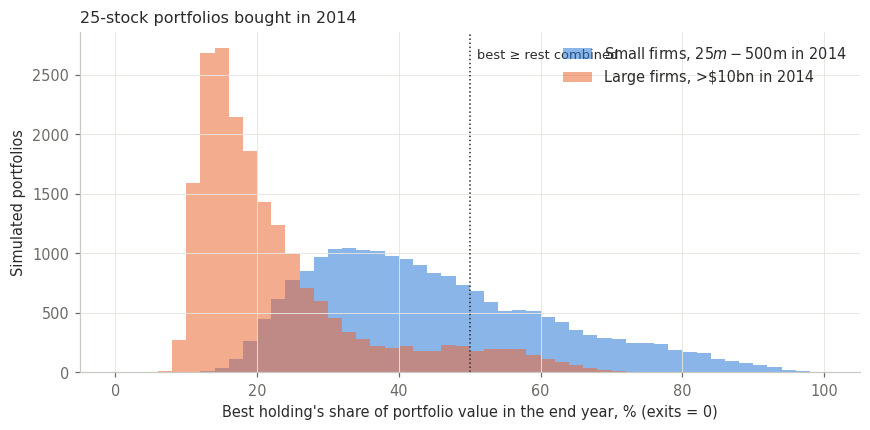

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
for i, (lab, u) in enumerate([("Small firms, $25m-$500m in 2014", small), ("Large firms, >$10bn in 2014", large)]):
    m = np.clip((b.reindex(u) / a[u]).fillna(0.0).values, 0, None)
    d = m[np.random.default_rng(1).integers(0, len(m), (20000, 25))]
    s = d.max(1) / np.where(d.sum(1) > 0, d.sum(1), np.nan)
    ax.hist(s[~np.isnan(s)] * 100, bins=np.linspace(0, 100, 51), color=tc.C[i], alpha=0.55, label=lab)
ax.axvline(50, color=tc.INK, ls=":", lw=1); ax.text(51, ax.get_ylim()[1] * 0.92, "best ≥ rest combined", fontsize=8.5)
ax.set_xlabel("Best holding's share of portfolio value in the end year, % (exits = 0)")
ax.set_ylabel("Simulated portfolios"); ax.legend(loc="upper right")
ax.set_title("25-stock portfolios bought in 2014", loc="left"); fig.tight_layout(); tc.save_fig(fig, "h1_fig4_portfolios")

## Part B · Startups: the Y Combinator directory

YC is the closest available public record of an early-stage venture portfolio: 6,000+ companies with batch, status and team size. For ages, we use only batches from 2019 or earlier, since later companies have had less than about seven years to resolve.

In [10]:
yc = tc.yc_companies()
print(f"{len(yc):,} companies, batches {int(yc.batch_year.min())}-{int(yc.batch_year.max())}")
print(yc.status.value_counts().to_string())
mature = yc[yc.batch_year <= 2019]
out = (pd.crosstab(mature.batch_year, mature.status, normalize="index") * 100)
out = out.reindex(columns=["Public", "Acquired", "Active", "Inactive"]).fillna(0)
tc.save_table(out, "h1_yc_outcomes_by_year")
out.round(1)

6,369 companies, batches 2005-2027
status
Active      4401
Inactive    1105
Acquired     840
Public        23


status,Public,Acquired,Active,Inactive
batch_year,,,,
2005.0,0.0,62.5,0.0,37.5
2006.0,0.0,35.3,5.9,58.8
2007.0,3.0,39.4,9.1,48.5
2008.0,0.0,20.9,7.0,72.1
2009.0,2.4,28.6,19.0,50.0
2010.0,3.2,47.6,11.1,38.1
2011.0,0.0,41.9,22.9,35.2
2012.0,2.7,30.9,22.8,43.6
2013.0,1.0,34.7,27.6,36.7


### Figure H1-5 · What happened to YC companies, by batch year

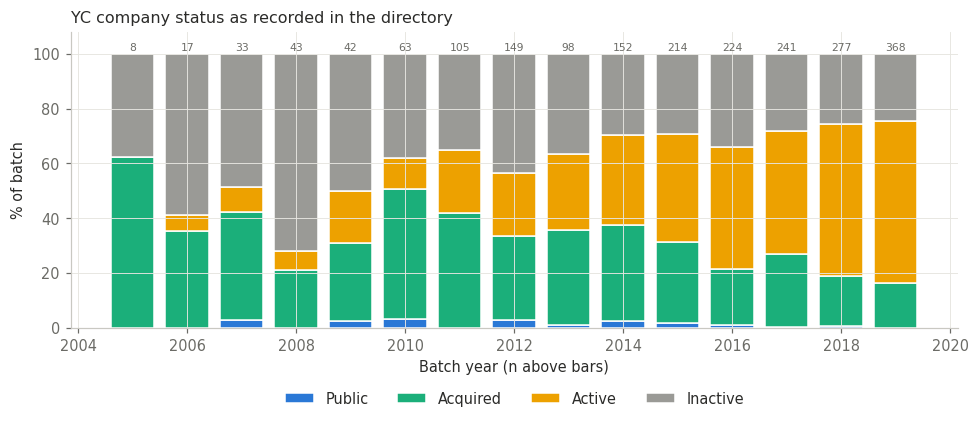

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
bottom = np.zeros(len(out))
cols = {"Public": tc.C[0], "Acquired": tc.C[2], "Active": tc.C[3], "Inactive": tc.GREY}
for s in out.columns:
    ax.bar(out.index, out[s], bottom=bottom, color=cols[s], label=s, width=0.8, edgecolor="white", linewidth=1)
    bottom += out[s].values
n = mature.groupby("batch_year").size()
for x, v in n.items(): ax.text(x, 101, f"{v}", ha="center", fontsize=7, color=tc.MUTED)
ax.set_ylim(0, 108); ax.set_ylabel("% of batch"); ax.set_xlabel("Batch year (n above bars)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=4)
ax.set_title("YC company status as recorded in the directory", loc="left")
fig.tight_layout(); tc.save_fig(fig, "h1_fig5_yc_outcomes")

### H1a for startups · Team-size tail, and whether each batch's biggest company outweighs the rest

"Batch" means a single season (for example, Winter 2012), the closest analogue to a fund vintage. We keep batches with at least 20 companies that report a team size.

In [12]:
ts = yc[(yc.team_size >= 1) & (yc.batch_year <= 2019)].copy()
f_yc = tc.tail_fit(ts.team_size.values)
c_yc = tc.compare_tails(f_yc["fit"])
by = ts.groupby("batch").agg(n=("team_size", "size"), total=("team_size", "sum"), best=("team_size", "max"),
                             best_name=("team_size", lambda s: ts.loc[s.idxmax(), "name"]),
                             year=("batch_year", "first"))
by = by[by.n >= 20].sort_values("year")
by["best_share"] = by.best / by.total
by["best_ge_rest"] = by.best >= (by.total - by.best)
tc.save_table(by, "h1_yc_batches")
yc_stats = {"n_companies": len(ts), "alpha": f_yc["alpha"], "alpha_se": f_yc["se"], "xmin": f_yc["xmin"],
            "R_pl_vs_lognormal": c_yc["R_pl_vs_lognormal"], "p": c_yc["p"],
            "top1pct_share_of_employees": tc.top_share(ts.team_size, frac=0.01),
            "top_company_flag_share_of_firms": ts.top_company.mean(),
            "top_company_flag_share_of_employees": ts.loc[ts.top_company, "team_size"].sum() / ts.team_size.sum(),
            "batches": len(by), "share_batches_best_ge_rest": by.best_ge_rest.mean(),
            "median_best_share": by.best_share.median()}
print(pd.Series(yc_stats).round(3).to_string())
by[["n", "best_name", "best", "total", "best_share", "best_ge_rest"]].round(2)

n_companies                            1906.000
alpha                                     2.006
alpha_se                                  0.066
xmin                                    150.000
R_pl_vs_lognormal                        -0.559
p                                         0.576
top1pct_share_of_employees                0.410
top_company_flag_share_of_firms           0.046
top_company_flag_share_of_employees       0.500
batches                                  21.000
share_batches_best_ge_rest                0.190
median_best_share                         0.290


,n,best_name,best,total,best_share,best_ge_rest
batch,,,,,,
Summer 2009,23,Stripe,7000.0,7957.0,0.88,True
Summer 2010,32,PagerDuty,950.0,2103.0,0.45,False
Winter 2010,22,Optimizely,1500.0,1918.0,0.78,True
Summer 2011,58,GoCardless,900.0,4126.0,0.22,False
Winter 2011,43,GOAT Group,1600.0,3242.0,0.49,False
Winter 2012,58,Gusto,2400.0,7299.0,0.33,False
Summer 2012,76,Coinbase,6112.0,13321.0,0.46,False
Summer 2013,48,DoorDash,8600.0,10799.0,0.80,True
Winter 2013,42,Fivetran,1200.0,3647.0,0.33,False


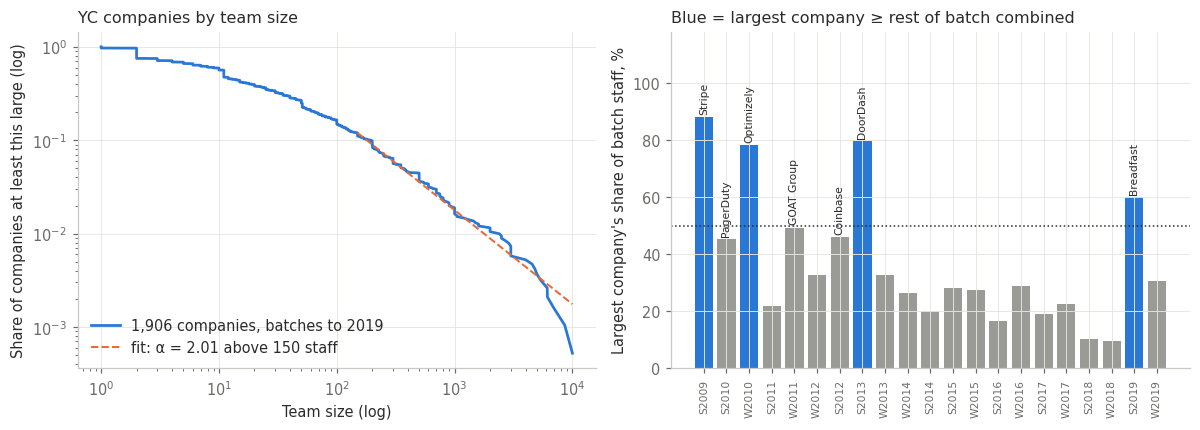

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x, p = tc.ccdf(ts.team_size.values)
axes[0].loglog(x, p, color=tc.C[0], lw=1.8, label=f"{len(ts):,} companies, batches to 2019")
xm = f_yc["xmin"]; frac = (ts.team_size >= xm).mean(); xx = np.logspace(np.log10(xm), np.log10(x.max()), 40)
axes[0].loglog(xx, frac * (xx / xm) ** (1 - f_yc["alpha"]), color=tc.C[1], ls="--", lw=1.3,
               label=f"fit: α = {f_yc['alpha']:.2f} above {xm:.0f} staff")
axes[0].set_xlabel("Team size (log)"); axes[0].set_ylabel("Share of companies at least this large (log)")
axes[0].set_title("YC companies by team size", loc="left"); axes[0].legend(loc="lower left")
ax = axes[1]
ax.bar(range(len(by)), by.best_share * 100, color=[tc.C[0] if v else tc.GREY for v in by.best_ge_rest], width=0.8)
ax.axhline(50, color=tc.INK, ls=":", lw=1)
ax.set_xticks(range(len(by))); ax.set_xticklabels(by.index.str.replace("Winter ", "W").str.replace("Summer ", "S")
                                                  .str.replace("Spring ", "Sp").str.replace("Fall ", "F"), rotation=90, fontsize=7)
for i, (nm, sh) in enumerate(zip(by.best_name, by.best_share)):
    if sh >= 0.35: ax.text(i, sh * 100 + 1, nm, rotation=90, fontsize=7, ha="center", va="bottom")
ax.set_ylim(0, 118); ax.set_ylabel("Largest company's share of batch staff, %")
ax.set_title("Blue = largest company ≥ rest of batch combined", loc="left")
fig.tight_layout(); tc.save_fig(fig, "h1_fig6_yc_tail_batches")

## Verdict inputs and check cell — send me this output

In [14]:
summary = {
    "years": [int(dist.index.min()), int(END)],
    "alpha_top500_2011_14": round(pre.alpha_top500.mean(), 3), "alpha_top500_post": round(post.alpha_top500.mean(), 3),
    "alpha_top500_base_end": [round(dist.alpha_top500[BASE], 3), round(dist.alpha_top500[END], 3)],
    "alpha_2011_14": round(pre.alpha.mean(), 3), "alpha_post": round(post.alpha.mean(), 3),
    "alpha_base_end": [round(dist.alpha[BASE], 3), round(dist.alpha[END], 3)],
    "R_p_base_end": [[round(dist.R_pl_vs_lognormal[y], 2), round(dist.p[y], 3)] for y in (BASE, END)],
    "top10_share_base_end": [round(dist.top10_share[BASE], 4), round(dist.top10_share[END], 4)],
    "top1pct_share_base_end": [round(dist.top1pct_share[BASE], 4), round(dist.top1pct_share[END], 4)],
    "wealth_creation": {k: (None if pd.isna(v) else round(float(v), 3)) for k, v in wc.items()},
    "top5_creators": top.head(5).to_dict("records"),
    "portfolio_sim": sim.round(3).reset_index().to_dict("records"),
    "yc": {k: round(float(v), 3) for k, v in yc_stats.items()},
    "yc_outcomes_2005_2012_mean": out.loc[:2012].mean().round(1).to_dict(),
}
(tc.OUT / "h1_summary.json").write_text(json.dumps(summary, indent=1, default=str))
print(json.dumps(summary, indent=1, default=str))

{
 "years": [
  2011,
  2025
 ],
 "alpha_top500_2011_14": 1.94,
 "alpha_top500_post": 1.88,
 "alpha_top500_base_end": [
  1.949,
  1.824
 ],
 "alpha_2011_14": 2.124,
 "alpha_post": 2.086,
 "alpha_base_end": [
  2.107,
  2.268
 ],
 "R_p_base_end": [
  [
   -1.79,
   0.074
  ],
  [
   -1.76,
   0.078
  ]
 ],
 "top10_share_base_end": [
  0.1425,
  0.3324
 ],
 "top1pct_share_base_end": [
  0.3987,
  0.5193
 ],
 "wealth_creation": {
  "firms_2014": 6964.0,
  "survivors": 2879.0,
  "exits": 4085.0,
  "entrants": 2291.0,
  "survivor_share_losing_pct": 35.186,
  "net_gain_neutral_tn": 36.657,
  "net_gain_lower_tn": 32.558,
  "entrant_value_tn": 6.331,
  "k_all_gain_neutral": 401.0,
  "k_all_gain_lower": 155.0,
  "top10_share_of_net_neutral_pct": 49.883,
  "k_pct_of_2014_cohort_neutral": 5.758,
  "k_pct_of_2014_cohort_lower": 2.226
 },
 "top5_creators": [
  {
   "firm": "NVIDIA CORP",
   "gain_bn": 3991.0,
   "cum_share_of_net_pct": 10.9
  },
  {
   "firm": "MICROSOFT CORPORATION",
   "gain_bn"